# 4 · Strategies, one fair comparison

`3_upscale_web.ipynb` made one architecture fast, and `7_upscale_luma.ipynb` found a
better one. This notebook asks which *ideas* are worth keeping, by training each of them
with the same data, the same recipe and the same seed - and by measuring how far apart
the same model lands when only luck changes, because a smaller gap than that says nothing.

Every strategy keeps notebook 3's frame (frozen bicubic skip, residual at low resolution,
one `PixelShuffle`), fits the client's 4-pixel halo, and uses only operators inside the
browser's fast set. They differ in the body, and they test five ideas:

- **Reparameterization** - each convolution trained as three branches and merged into one
  afterwards: more to learn with, the same graph to run. Free.
- **Luma only** - the network corrects brightness and leaves colour to bicubic
  (notebook 7): less to run, and colour cannot drift. Free.
- **Residual blocks** - a deeper body inside the same halo (notebook 7). Paid in memory traffic.
- **A colour branch** - a narrow network of its own for colour: can a model beat bicubic
  at colour, which the codec sent at a quarter of the resolution? Paid in arithmetic.
- **Leaky ReLU** - at 1e-3 the control switches off 6 of its 16 narrow channels within its
  first 60 steps; a leaky ReLU cannot switch a channel off for good. Free.

Steps:

1. **Data** - load the patch pairs, and how a patch is scored.
2. **Models** - every strategy, its size, and how far it reaches (measured, not assumed).
3. **Speed** - is each fast enough for a live stream? Checked before training.
4. **Train** - every strategy until it has converged, then the control again at other
   seeds: the gap luck alone makes.
5. **Save** - the winner, in the form that ships, and a whole frame through it.
6. **Export** - the best two at the client's tile.

Needs: `0_data_preprocess.ipynb`. Results: `summary.md`, "Strategies".
Writes `checkpoints/upscale_strategies.pt`, and each run's training to `checkpoints/strategy_runs/`.

In [1]:
"""Settings."""

import copy

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from PIL import Image

from helpers import metrics, models, speed, tiles, training, webexport
from helpers.training import DATA_DIR, DEVICE

CHECKPOINT = training.CHECKPOINT_DIR / "upscale_strategies.pt"   # the winner, as it ships
RUN_DIR = training.CHECKPOINT_DIR / "strategy_runs"               # each run's training, saved every epoch
FRAME_DIR = DATA_DIR / "synthetic"

EXPAND = 4           # how much wider the extra branch of a reparameterized convolution is
MAX_EPOCHS = 500     # a safety limit; each training stops by itself once it has converged
BATCH_SIZE = 32
LEARNING_RATE = 1e-3 # where a training starts, unless its strategy sets its own (see "2. Models")
SEED = 0
REPEATS = [          # the control trained again: how far apart luck alone puts two runs
    {"seed": 1},
    {"seed": 2},
    {"seed": 0, "learning_rate": 3e-4},   # and what the reparameterized models' rate does to it
]
PUBLISH = 2          # how many of the best strategies to export

STEP_WIDTH, STEP_HEIGHT = 320, 180       # LR pixels one client tile adds to the picture (notebook 5)
FRAME_WIDTH, FRAME_HEIGHT = 1920, 1080   # the whole-frame graph
ESTIMATE_ON = {                          # devices for the runtime estimate (speed.HARDWARE)
    "Iris Xe": "Intel Iris Xe, 96 EU (laptop iGPU)",
    "GTX 1650": "NVIDIA GTX 1650",
    "RTX 3060": "NVIDIA RTX 3060",
}

training.seed_everything(SEED)

## 1. Data

`train` is what the models learn from, with random flips and rotations as free extra
examples. `val` is held out: every score below is measured on it.

The LR patches carry a halo of extra pixels, so a model's output is a bit too large;
`trim` cuts that border off before the loss and the scores.

device  cuda NVIDIA GeForce RTX 3090
scale   2
patch   72 px LR in (64 px + a halo of 4) -> 128 px HR out, 8 frames each
train  11117 patches from 697 sources
val     2369 patches from 149 sources
lr batch (32, 3, 72, 72)  hr batch (32, 3, 128, 128)


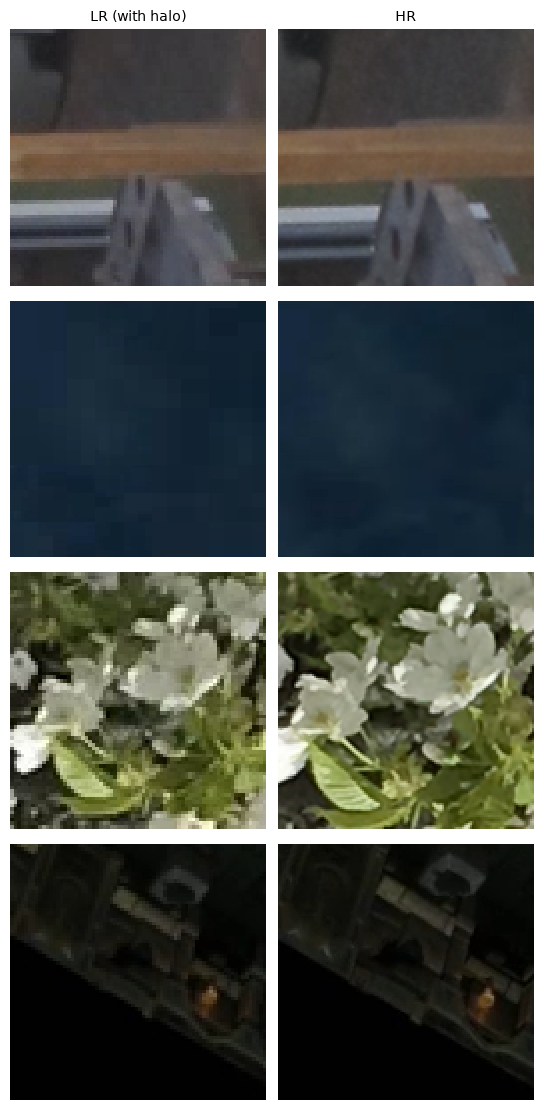

In [2]:
manifest = training.load_manifest()
training.describe(manifest)
SCALE = manifest["scale"]
train_loader, val_loader = training.loaders(DATA_DIR, manifest, BATCH_SIZE, val_batch_size=128)
trim = training.trimmer(manifest)

lr_batch, hr_batch = next(iter(train_loader))
print("lr batch", tuple(lr_batch.shape), " hr batch", tuple(hr_batch.shape))
training.show_patches({"LR (with halo)": lr_batch[:4], "HR": hr_batch[:4]})

### How a patch is scored

Every score comes from `metrics.report`, and it weighs brightness above colour, because
the eye does. Take one patch and damage it twice with the *same amount* of noise, once in
brightness (Y) and once in colour (U, V): RGB PSNR calls the two about equal, but the
colour damage is nearly invisible.

- `ssim-y` - structure on brightness: edges and contrast in 11x11 windows. Every training
  keeps the epoch with the best one, as in notebooks 2, 3 and 7, and the strategies are
  ranked by it.
- `wpsnr` - the brightness error weighted 6 times either colour error, then in dB.
  `wpsnr_db` averages the three dB numbers 6:1:1 instead (the convention in papers), and
  `chroma_subsample=2` scores colour at the resolution 4:2:0 video actually sends.

                        wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
brightness damaged      27.34    26.09    55.63    57.99     26.09   0.7313
colour damaged          35.22    57.89    26.21    61.84     25.57   0.9980

                       wpsnr  wpsnr_db  wpsnr 4:2:0     rgb
brightness damaged     27.34     33.77        27.34   26.09
colour damaged         35.22     54.43        41.11   25.57


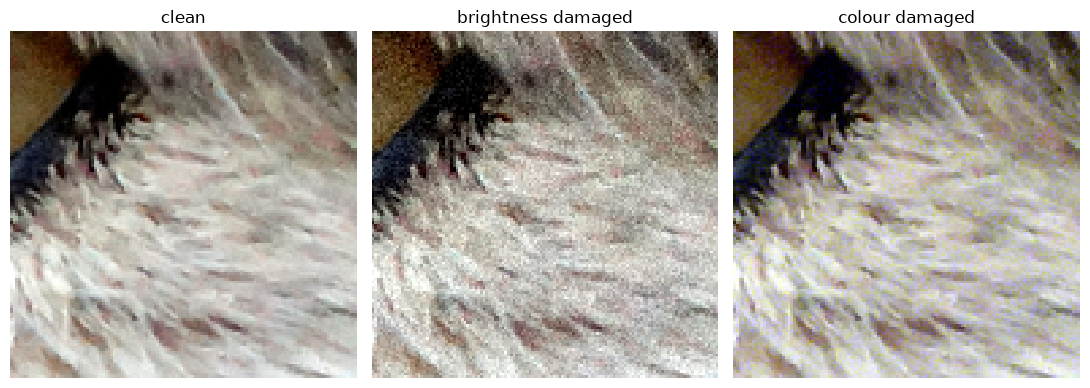

In [3]:
clean = val_loader.dataset[3][1][None]   # the HR target of one validation patch
noise = torch.randn(1, 1, *clean.shape[2:], generator=torch.Generator().manual_seed(SEED)) * 0.05
zero = torch.zeros_like(noise)
yuv = metrics.rgb_to_yuv(clean)
damaged = {
    "brightness damaged": metrics.yuv_to_rgb(yuv + torch.cat([noise, zero, zero], 1)),
    "colour damaged": metrics.yuv_to_rgb(yuv + torch.cat([zero, noise, zero], 1)),
}
metrics.print_table({name: metrics.report(image, clean) for name, image in damaged.items()})

print(f"\n{'':<20}{'wpsnr':>8}{'wpsnr_db':>10}{'wpsnr 4:2:0':>13}{'rgb':>8}")
for name, image in damaged.items():
    print(f"{name:<20}{metrics.wpsnr(image, clean):8.2f}{metrics.wpsnr_db(image, clean):10.2f}"
          f"{metrics.wpsnr(image, clean, chroma_subsample=2):13.2f}{metrics.psnr(image, clean):8.2f}")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for ax, (name, image) in zip(axes, {"clean": clean, **damaged}.items()):
    ax.imshow(image[0].clamp(0, 1).permute(1, 2, 0).numpy(), interpolation="nearest")
    ax.set_title(name)
    ax.axis("off")
fig.tight_layout()
plt.show()

## 2. Models

Every strategy is a `models.Upscaler`: it builds its own body and a `residual(x)`, and the
frame adds the bicubic skip and the `PixelShuffle`. The output convolution starts at zero,
so every untrained model is exactly bicubic.

    LR --> bicubic skip (fixed 5x5 conv) ------------------+
    LR --> body -> output conv (starts at zero) -----------+--> add --> PixelShuffle --> HR

| strategy | body | what it tests |
|---|---|---|
| `32-16` | notebook 3's model: 5x5 to 32, 3x3 to 16, RGB correction | the control |
| `32-16 leaky` | the same with a leaky ReLU | channels that cannot switch off |
| `32-16 reparam` | the same, trained as three branches per convolution | more to learn with, the same graph |
| `luma 32-16` | the control's body, correcting brightness only | colour left to bicubic |
| `luma 32-16 reparam` | the same, trained as branches | do the two free ideas add up? |
| `luma 24 + 2 blocks` | notebook 7's model | residual blocks |
| `luma 24 + 2 blocks reparam` | notebook 7's model, trained as branches | the best body and a free idea |
| `yuv split` | a 32-16 branch for brightness, an 8-4 one for colour | can colour beat bicubic? |

**Two learning rates.** A strategy starts at 1e-3 unless it does not learn there, and the
reparameterized ones without residual blocks do not. Three branches, all moving at once,
take a larger step on the merged kernel than one convolution does: in its first 20 steps
at 1e-3, `32-16 reparam` switches off 14 of its 16 narrow channels for good (a ReLU passes
no gradient to a channel that is negative everywhere) and the model is bicubic again,
which is why notebook 6's run at 1e-3 never beat bicubic. At 3e-4 they keep their
channels and learn as fast as the control does at 1e-3. A residual block adds its input
back, so a gradient always gets through, and `luma 24 + 2 blocks reparam` learns at 1e-3.
The control is also trained at 3e-4 in "4. Train", to show what the rate alone does.

Left out from the earlier version of this notebook (`summary.md`): `recursive` and `dense`
reach 6 and 5 pixels, beyond the 4-pixel halo of the patches and of the client's tiles,
and `attention` reads the whole tile and uses operators outside the browser's fast set.
None of them could ship.

The control, `models.PlainUpscaler`, the reparameterized `models.ReparamUpscaler` and the
luma `models.LumaUpscaler` are in `helpers/models.py`. The rest are defined here.

In [4]:
"""Strategies built on the classes in helpers/models.py."""


class LeakyUpscaler(models.PlainUpscaler):
    """`models.PlainUpscaler` with a leaky ReLU: a negative value passes at `slope` times its
    size instead of not at all, so a channel that is negative everywhere still learns. It
    exports as `LeakyRelu`, which is inside the browser's fast operators."""

    def __init__(self, widths=(32, 16), stem=5, slope=0.1, skip=5, scale=2):
        super().__init__(widths, stem, skip, scale)
        for index, layer in enumerate(self.body):
            if isinstance(layer, nn.ReLU):
                self.body[index] = nn.LeakyReLU(slope, inplace=True)


class RepBlock(nn.Module):
    """`models.ResidualBlock` with its 3x3 trained as a `models.RepConv`."""

    def __init__(self, width, expand=EXPAND):
        super().__init__()
        self.conv = models.RepConv(width, width, 3, expand)
        self.point = nn.Conv2d(width, width, 1)

    def forward(self, x):
        return x + self.point(torch.relu(self.conv(x)))


class RepLuma(models.Upscaler):
    """`models.LumaUpscaler` with every k x k convolution of its body trained as a
    `models.RepConv`. `collapsed()` merges the branches into the `LumaUpscaler` that ships."""

    def __init__(self, widths=(24,), blocks=2, stem=3, expand=EXPAND, skip=5, scale=2):
        super().__init__(scale, skip)
        self.widths, self.blocks, self.stem = tuple(widths), blocks, stem
        layers, channels = [], 3
        for index, width in enumerate(widths):
            kernel = stem if index == 0 else 3
            layers += [models.RepConv(channels, width, kernel, expand), nn.ReLU(inplace=True)]
            channels = width
        layers += [RepBlock(channels, expand) for _ in range(blocks)]
        self.body = nn.Sequential(*layers)
        self.tail = models.zero_start(nn.Conv2d(channels, scale * scale, 3, padding=1))
        self.halo = self.halo_for(stem, len(widths) - 1 + blocks + 1)

    def residual(self, x):
        luma = self.tail(self.body(x))
        return torch.cat([luma, luma, luma], dim=1)

    @torch.no_grad()
    def collapsed(self):
        """The same trained model as a `LumaUpscaler` - what gets exported."""
        plain = models.LumaUpscaler(self.widths, self.blocks, self.stem, self.skip_size, self.scale)
        for mine, theirs in zip(self.body, plain.body):   # layer for layer, the ReLUs too
            if isinstance(mine, models.RepConv):
                theirs.load_state_dict(mine.collapse().state_dict())
            elif isinstance(mine, RepBlock):
                theirs.conv.load_state_dict(mine.conv.collapse().state_dict())
                theirs.point.load_state_dict(mine.point.state_dict())
        plain.tail.load_state_dict(self.tail.state_dict())
        return plain.to(next(self.parameters()).device).eval()

In [5]:
"""The colour split: a wide branch for brightness, a narrow one for colour."""


def frozen_conv(weight):
    """A 1x1 convolution with fixed weights (out, in), not trained."""
    conv = nn.Conv2d(weight.shape[1], weight.shape[0], 1, bias=False)
    with torch.no_grad():
        conv.weight.copy_(weight[:, :, None, None])
    conv.weight.requires_grad_(False)
    return conv


def colour_matrix(matrix, phases):
    """A 3x3 colour matrix applied to each of `phases` interleaved copies of the channels."""
    weight = torch.zeros(3 * phases, 3 * phases)
    for out_channel in range(3):
        for in_channel in range(3):
            for phase in range(phases):
                weight[out_channel * phases + phase, in_channel * phases + phase] = matrix[out_channel, in_channel]
    return weight


def plain_body(widths, in_channels, stem):
    """stem x stem, then 3x3s, ReLU after each."""
    layers = []
    for index, width in enumerate(widths):
        kernel = stem if index == 0 else 3
        layers += [nn.Conv2d(in_channels, width, kernel, padding=kernel // 2), nn.ReLU(inplace=True)]
        in_channels = width
    return nn.Sequential(*layers), in_channels


class YuvSplit(models.Upscaler):
    """Convert to Y'CbCr, a wide branch for Y (brightness), a narrow one for U and V.

    `luma_sees=1`: the Y branch reads Y only. `luma_sees=3`: it reads Y, U and V.
    Y is taken with a 1x1 convolution rather than `x[:, :1]`, because a slice exports as
    `Slice`, which is outside the browser's fast operators.
    """

    def __init__(self, luma=(32, 16), chroma=(8, 4), luma_sees=1, stem=5, skip=5, scale=2):
        super().__init__(scale, skip)
        phases = scale ** 2
        self.luma_sees = luma_sees
        self.to_luma = frozen_conv(metrics.RGB_TO_YUV[:1])
        self.to_yuv = frozen_conv(metrics.RGB_TO_YUV)
        self.luma_body, luma_width = plain_body(luma, luma_sees, stem)
        self.luma_tail = models.zero_start(nn.Conv2d(luma_width, phases, 3, padding=1))
        self.chroma_body, chroma_width = plain_body(chroma, 3, stem)
        self.chroma_tail = models.zero_start(nn.Conv2d(chroma_width, 2 * phases, 3, padding=1))
        self.to_rgb = frozen_conv(colour_matrix(metrics.YUV_TO_RGB, phases))
        self.halo = self.halo_for(stem, max(len(luma), len(chroma)))

    def residual(self, x):
        yuv = self.to_yuv(x)
        luma = self.luma_tail(self.luma_body(yuv if self.luma_sees == 3 else self.to_luma(x)))
        chroma = self.chroma_tail(self.chroma_body(yuv))
        return self.to_rgb(torch.cat([luma, chroma], dim=1))

In [6]:
"""Every strategy: name -> (model class, its arguments, the learning rate it starts at)."""

STRATEGIES = {
    "32-16": (models.PlainUpscaler, {"widths": (32, 16), "stem": 5}, LEARNING_RATE),
    "32-16 leaky": (LeakyUpscaler, {"widths": (32, 16), "stem": 5}, LEARNING_RATE),
    "32-16 reparam": (models.ReparamUpscaler, {"widths": (32, 16), "stem": 5, "expand": EXPAND}, 3e-4),
    "luma 32-16": (models.LumaUpscaler, {"widths": (32, 16), "blocks": 0, "stem": 5}, LEARNING_RATE),
    "luma 32-16 reparam": (RepLuma, {"widths": (32, 16), "blocks": 0, "stem": 5, "expand": EXPAND}, 3e-4),
    "luma 24 + 2 blocks": (models.LumaUpscaler, {"widths": (24,), "blocks": 2, "stem": 3}, LEARNING_RATE),
    "luma 24 + 2 blocks reparam": (RepLuma, {"widths": (24,), "blocks": 2, "stem": 3, "expand": EXPAND},
                                   LEARNING_RATE),
    "yuv split": (YuvSplit, {"luma": (32, 16), "chroma": (8, 4), "stem": 5}, LEARNING_RATE),
}
CONTROL = "32-16"
COLOURS = {name: f"C{index}" for index, name in enumerate(STRATEGIES)}   # one colour per strategy, in every plot


def build(name):
    """A fresh, untrained model of one strategy."""
    model_class, arguments, _ = STRATEGIES[name]
    return model_class(scale=SCALE, **arguments).to(DEVICE)


def deployed(model):
    """The model as it ships: a reparameterized one merged into plain convolutions."""
    return model.eval().collapsed() if hasattr(model, "collapsed") else model


def slug(name):
    """A strategy's name as a file name: "luma 24 + 2 blocks" -> "luma_24_2_blocks"."""
    return "_".join(name.replace("+", " ").split())

### Size, reach and start

- **learned parameters** and **MACs per LR pixel** (multiply-adds), while training and as
  shipped: a reparameterized model trains with about four times the arithmetic and ships
  with none of it.
- **halo** - how far a model reaches. Each class declares it, and it is also *measured*:
  set every weight to a small positive number, send a gradient back from one output pixel,
  and see how far into the input it arrives. It must be at most the patches' halo (4), or
  the model would learn from zero padding and show seams between the client's tiles.
- **vs bicubic** - the largest difference between the untrained model and bicubic on
  validation patches: every strategy has to start exactly there.

In [7]:
def measured_halo(model, size=33):
    """How far one output pixel reaches into the input, in LR pixels."""
    model = copy.deepcopy(model).cpu()
    with torch.no_grad():
        for module in model.modules():
            if isinstance(module, nn.Conv2d):
                module.weight.fill_(0.05)
                if module.bias is not None:
                    module.bias.zero_()
    x = torch.ones(1, 3, size, size, requires_grad=True)
    centre = size // 2
    model(x)[0, :, centre * SCALE, centre * SCALE].sum().backward()
    reach = x.grad.abs().sum(dim=(0, 1))
    rows = torch.nonzero(reach.sum(dim=1)).flatten()
    cols = torch.nonzero(reach.sum(dim=0)).flatten()
    return int(max(centre - rows.min(), rows.max() - centre, centre - cols.min(), cols.max() - centre))


models.check_skip_is_bicubic(SCALE)
lr_probe = next(iter(val_loader))[0][:8].to(DEVICE)

built = {}
print(f"{'strategy':<28}{'learned params':>18}{'MACs / LR px':>18}{'halo':>6}{'measured':>10}{'vs bicubic':>12}")
for name in STRATEGIES:
    torch.manual_seed(SEED)
    built[name] = model = build(name)
    shipped = deployed(model)
    reach = measured_halo(model)
    assert reach == model.halo, f"{name}: declares a halo of {model.halo}, reaches {reach}"
    assert model.halo <= manifest["halo"], f"{name}: reaches further than the patches' halo"
    with torch.no_grad(), training.full_precision():
        start = (trim(model(lr_probe)) - trim(models.bicubic(lr_probe, SCALE))).abs().max().item()
    assert start < 1e-5, f"{name}: the untrained model is not bicubic ({start:.1e})"
    params = f"{models.count_parameters(model, True):,} -> {models.count_parameters(shipped, True):,}"
    macs = f"{speed.macs_per_lr_pixel(model):,.0f} -> {speed.macs_per_lr_pixel(shipped):,.0f}"
    print(f"{name:<28}{params:>18}{macs:>18}{model.halo:6}{reach:10}{start:12.1e}")

strategy                        learned params      MACs / LR px  halo  measured  vs bicubic
32-16                           8,796 -> 8,796    9,636 -> 9,636     4         4     4.2e-07
32-16 leaky                     8,796 -> 8,796    9,636 -> 9,636     4         4     4.2e-07


32-16 reparam                  41,664 -> 8,796   42,408 -> 9,636     4         4     4.2e-07
luma 32-16                      7,636 -> 7,636    8,484 -> 8,484     4         4     4.2e-07
luma 32-16 reparam             40,504 -> 7,636   41,256 -> 8,484     4         4     4.2e-07
luma 24 + 2 blocks            13,156 -> 13,156  13,932 -> 13,932     4         4     4.2e-07
luma 24 + 2 blocks reparam    63,232 -> 13,156  63,864 -> 13,932     4         4     4.2e-07
yuv split                       7,232 -> 7,232    8,216 -> 8,216     4         4     4.2e-07


## 3. Speed - is each fast enough?

A model that misses the frame time is no use for a live stream, however good it looks.
Speed depends on the shape, not the weights, so it is checked before training - on the
graph that ships, a reparameterized model merged first. Each graph must also use only
operators inside the browser's fast set.

As in notebook 3: `webexport.count_work` counts the operations (a multiply-add is 2) and
the memory traffic in the ONNX graph of one client tile (640x360 out, plus the halo), and
a frame costs that times its tiles. The **roofline** estimate gives a device the slower of
*operations / peak compute* and *bytes / bandwidth*. This computer's GPU runs the control
to see what share of its peak it reaches, and every device is assumed to reach that same
share - one share for every strategy, so the estimates rank them by their work, not by how
well one GPU's kernels suit each shape. The `measured` column is one whole 1080p frame
through torch on this computer. A browser usually reaches less, so read the estimates as
a best case: 16.7 ms is a 60 fps frame, 33.3 ms a 30 fps one.

In [8]:
"""The work in one client tile of each strategy, and the time for a 1080p frame."""

plan = tiles.plan_tiling((FRAME_WIDTH, FRAME_HEIGHT), scale=SCALE, halo=manifest["halo"])
tile_input = plan["input"][2:]   # (height, width) of one tile, halo included
frame_lr = torch.rand(1, 3, FRAME_HEIGHT // SCALE, FRAME_WIDTH // SCALE, device=DEVICE)


def per_frame(work, pixels, runs):
    """Operations and bytes for `pixels` LR pixels computed in `runs` runs of a graph."""
    return {"operations": pixels * work["operations"] / work["input_pixels"],
            "bytes": pixels * work["activation_bytes"] / work["input_pixels"] + runs * work["weight_bytes"]}


costs = {}
for name, model in built.items():
    shipped = deployed(model)
    # into checkpoints/, not dist/, so the benchmark page does not list it
    graph = webexport.export(shipped, f"speed_check_{slug(name)}.onnx", tile_input, halo=shipped.halo,
                             models_dir=training.CHECKPOINT_DIR / "speed")
    assert not graph["outside_budget"], f"{name} uses {graph['outside_budget']}, outside the fast operators"
    work = webexport.count_work(graph["path"])
    with torch.no_grad():
        measured_ms = speed.time_ms(lambda: shipped(frame_lr), seconds=1.0)
    costs[name] = {"work": work, "measured_ms": measured_ms,
                   "ops": work["operations"] / work["input_pixels"],
                   "bytes": work["activation_bytes"] / work["input_pixels"]}

# calibrate: the share of its peak this GPU reaches on the control, as one whole frame
if DEVICE.type == "cuda":
    whole = per_frame(costs[CONTROL]["work"], frame_lr[0, 0].numel(), 1)
    best_ms, _ = speed.roofline_ms(whole, *speed.HARDWARE[speed.THIS_GPU])
    efficiency = best_ms / costs[CONTROL]["measured_ms"]
    print(f"{speed.THIS_GPU} reaches {efficiency:.0%} of its peak on the control; every estimate assumes the same")
else:
    efficiency = 1.0
    print("no GPU here to calibrate on: the estimates below are the roofline itself, a best case")

computed = plan["runs"] * plan["input"][2] * plan["input"][3]   # LR pixels of a 1080p frame's tiles, halos included
print(f"\nms per 1080p frame, {plan['runs']} tiles of {tile_input[1]}x{tile_input[0]} "
      f"(c = compute-bound, m = memory-bound)")
print(f"{'strategy':<28}{'ops / LR px':>12}{'bytes / LR px':>15}{'measured':>10}"
      + "".join(f"{short:>12}" for short in ESTIMATE_ON))
for name, cost in costs.items():
    row = f"{name:<28}{cost['ops']:12,.0f}{cost['bytes']:15,.0f}{cost['measured_ms']:10.2f}"
    for short, device in ESTIMATE_ON.items():
        ms, limit = speed.roofline_ms(per_frame(cost["work"], computed, plan["runs"]), *speed.HARDWARE[device])
        cost[short] = ms / efficiency
        row += f"{cost[short]:>9.1f} ({limit[0]})"
    print(row)

NVIDIA RTX 3090 reaches 38% of its peak on the control; every estimate assumes the same

ms per 1080p frame, 9 tiles of 328x188 (c = compute-bound, m = memory-bound)
strategy                     ops / LR px  bytes / LR px  measured     Iris Xe    GTX 1650    RTX 3060
32-16                             19,392          1,128      1.63     24.1 (m)     12.8 (m)      4.5 (m)
32-16 leaky                       19,392          1,128      1.64     24.1 (m)     12.8 (m)      4.5 (m)
32-16 reparam                     19,392          1,128      1.63     24.1 (m)     12.8 (m)      4.5 (m)
luma 32-16                        17,080          1,192      1.62     25.4 (m)     13.5 (m)      4.8 (m)
luma 32-16 reparam                17,080          1,192      1.62     25.4 (m)     13.5 (m)      4.8 (m)
luma 24 + 2 blocks                28,120          2,536      3.20     54.1 (m)     28.8 (m)     10.2 (m)
luma 24 + 2 blocks reparam        28,120          2,536      3.21     54.1 (m)     28.8 (m)     10.2 (

## 4. Train

The recipe of notebooks 2, 3 and 7, for every strategy: Adam, batch 32, the loss
`metrics.ssim_l1_loss` (0.84 x (1 - SSIM on luma) + 0.16 x L1 on RGB), and after every
epoch the epoch with the best luma SSIM (`ssim-y`) is kept. Each strategy trains until it
stops getting better - the learning rate halves whenever the score stalls, and training
stops once a hundredth of the starting rate brings nothing more - so each gets as many
epochs as it needs. Every training starts from the same seed, which also gives every
strategy the same batches in the same order.

Each run saves its training to `checkpoints/strategy_runs/` after every epoch: run the cell
again after an interruption and it carries on, and finished runs just load. Delete a run's
file to train it again, e.g. after changing its strategy. The first run of this section
takes a few hours.

In [9]:
def train(name, seed=SEED, **settings):
    """Train a fresh model of one strategy, or load its saved training. Returns the model
    at its best epoch, the per-epoch history and the best epoch."""
    _, _, learning_rate = STRATEGIES[name]
    settings = {"learning_rate": learning_rate, **settings}
    run = f"{slug(name)}_seed{seed}_lr{settings['learning_rate']:g}"
    torch.manual_seed(seed)
    model = build(name)
    torch.manual_seed(seed)   # the same batches in the same order, whatever the model's size
    history, best = training.train(model, train_loader, val_loader, trim, MAX_EPOCHS,
                                   loss_fn=metrics.ssim_l1_loss, select="ssim",
                                   checkpoint=RUN_DIR / f"{run}.pt", verbose=0, **settings)
    print(f"{name:<28} seed {seed}, from {settings['learning_rate']:.0e}: best epoch {best['epoch']:3} "
          f"of {len(history):3}, ssim-y {best['score']:.4f}")
    return model, history, best


baseline = training.evaluate(models.Resize(SCALE).to(DEVICE), val_loader, trim)
trained, histories, bests, results = {}, {}, {}, {"bicubic": baseline}
for name in STRATEGIES:
    trained[name], histories[name], bests[name] = train(name)
    results[name] = training.evaluate(trained[name], val_loader, trim)

32-16                        seed 0, from 1e-03: best epoch  98 of 116, ssim-y 0.9261


32-16 leaky                  seed 0, from 1e-03: best epoch  98 of 110, ssim-y 0.9266


32-16 reparam                seed 0, from 3e-04: best epoch 109 of 121, ssim-y 0.9265


luma 32-16                   seed 0, from 1e-03: best epoch 141 of 147, ssim-y 0.9264


luma 32-16 reparam           seed 0, from 3e-04: best epoch 100 of 112, ssim-y 0.9265


luma 24 + 2 blocks           seed 0, from 1e-03: best epoch  98 of 116, ssim-y 0.9286


luma 24 + 2 blocks reparam   seed 0, from 1e-03: best epoch  98 of 104, ssim-y 0.9285


yuv split                    seed 0, from 1e-03: best epoch 111 of 123, ssim-y 0.9265


### How big must a difference be?

One training is partly luck: another seed starts from other weights and sees the batches
in another order. So the control is trained again at two more seeds. Every strategy is
then compared with the *mean* of the control's three runs - not with one of them, which may
be its luckiest or its unluckiest - and a gap no wider than the spread of those three runs
is luck. Then the control once more from 3e-4, the rate the reparameterized models start
at, to see how much of their result is the rate.

In [10]:
def run_label(run):
    rate = run.get("learning_rate")
    return f"seed {run['seed']}" + (f", from {rate:.0e}" if rate else "")


repeats = {"seed 0": results[CONTROL]}
for run in REPEATS:
    model, _, _ = train(CONTROL, **run)
    repeats[run_label(run)] = training.evaluate(model, val_loader, trim)
print()
metrics.print_table(repeats)

seeds = [repeats[run_label(run)] for run in [{"seed": SEED}, *REPEATS] if "learning_rate" not in run]
spread = {key: max(s[key] for s in seeds) - min(s[key] for s in seeds) for key in ("ssim", "wpsnr")}
control_mean = {key: float(np.mean([s[key] for s in seeds])) for key in ("ssim", "wpsnr")}
print(f"\nthe control at {len(seeds)} seeds: {spread['ssim']:.4f} ssim-y and {spread['wpsnr']:.2f} dB wpsnr apart, "
      f"a mean of {control_mean['ssim']:.4f} ssim-y and {control_mean['wpsnr']:.2f} dB wpsnr")

32-16                        seed 1, from 1e-03: best epoch 135 of 141, ssim-y 0.9263


32-16                        seed 2, from 1e-03: best epoch  97 of 109, ssim-y 0.9265


32-16                        seed 0, from 3e-04: best epoch 136 of 148, ssim-y 0.9260



                        wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
seed 0                  37.91    37.07    44.60    45.39     35.55   0.9261
seed 1                  37.88    37.04    44.60    45.39     35.55   0.9263
seed 2                  38.01    37.18    44.64    45.47     35.63   0.9265
seed 0, from 3e-04      37.93    37.10    44.58    45.42     35.57   0.9260

the control at 3 seeds: 0.0004 ssim-y and 0.13 dB wpsnr apart, a mean of 0.9263 ssim-y and 37.93 dB wpsnr


### The result

Every strategy against the mean of the control's seeds, best first. **better** or
**worse** means the gap is wider than the seeds' spread; **luck** means this validation set
cannot tell the two apart. Ranked by `ssim-y`; `wpsnr` gets its own verdict in the second
table, because it is where keeping colour at bicubic shows.

In [11]:
order = sorted(STRATEGIES, key=lambda name: -results[name]["ssim"])
best_name = order[0]


def compare(name, key):
    """A strategy's gap to the mean of the control's seeds, and whether it is more than luck."""
    gap = results[name][key] - control_mean[key]
    if name == CONTROL:
        return gap, "control"
    return gap, "luck" if abs(gap) <= spread[key] else ("better" if gap > 0 else "worse")


def verdict(name, scores):
    """The last column of the table: ssim-y against the control."""
    if name == "bicubic":
        return ""
    gap, word = compare(name, "ssim")
    return f"{gap:+11.4f}  {word}"


print(f"last column: ssim-y against the control's mean of {control_mean['ssim']:.4f}")
metrics.print_table({name: results[name] for name in ["bicubic", *order]}, extra=verdict)

print(f"\n{'strategy':<28}{'ssim-y vs bicubic':>18}{'wpsnr vs control':>22}{'epochs':>8}{'ops / LR px':>13}"
      + "".join(f"{short:>10}" for short in ESTIMATE_ON) + "   ms per 1080p frame (estimate)")
for name in order:
    gap, word = compare(name, "wpsnr")
    print(f"{name:<28}{results[name]['ssim'] - baseline['ssim']:+18.4f}{gap:+14.2f}  {word:<6}"
          f"{len(histories[name]):8}{costs[name]['ops']:13,.0f}"
          + "".join(f"{costs[name][short]:10.1f}" for short in ESTIMATE_ON))
print(f"\nbest: {best_name}")

last column: ssim-y against the control's mean of 0.9263
                                wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
bicubic                         37.30    36.38    47.06    47.27     35.00   0.9135
luma 24 + 2 blocks              38.20    37.36    47.10    47.30     35.67   0.9286    +0.0023  better
luma 24 + 2 blocks reparam      38.18    37.34    47.10    47.31     35.65   0.9285    +0.0022  better
32-16 leaky                     38.04    37.21    44.67    45.50     35.65   0.9266    +0.0003  luck
yuv split                       37.99    37.15    45.15    45.76     35.60   0.9265    +0.0002  luck
32-16 reparam                   38.01    37.18    44.64    45.43     35.63   0.9265    +0.0002  luck
luma 32-16 reparam              37.97    37.11    47.09    47.29     35.48   0.9265    +0.0002  luck
luma 32-16                      38.07    37.21    47.09    47.29     35.58   0.9264    +0.0002  luck
32-16                           37.91    37.07    44.60    45.39

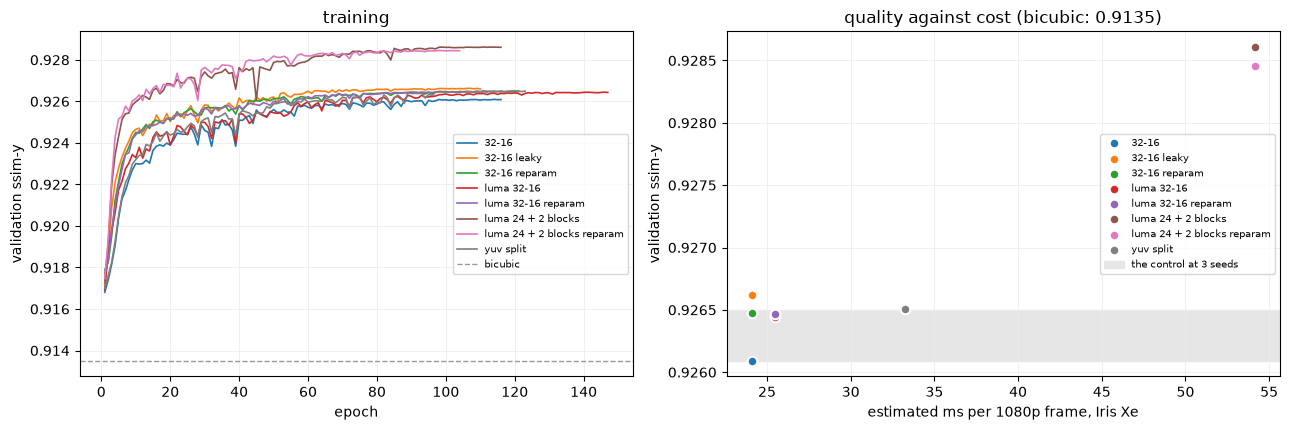

In [12]:
"""Training curves, and quality against cost."""

device = next(iter(ESTIMATE_ON))
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.4))
for name in STRATEGIES:
    epochs = range(1, len(histories[name]) + 1)
    left.plot(epochs, [h["ssim"] for h in histories[name]], color=COLOURS[name], linewidth=1.2, label=name)
    right.scatter(costs[name][device], results[name]["ssim"], color=COLOURS[name], s=48, zorder=3,
                  edgecolors="white", linewidths=1.5, label=name)
right.axhspan(min(s["ssim"] for s in seeds), max(s["ssim"] for s in seeds), color="0.9", zorder=1,
              label=f"the control at {len(seeds)} seeds")
left.axhline(baseline["ssim"], color="0.6", linestyle="--", linewidth=1, label="bicubic")
for ax in (left, right):
    ax.grid(color="0.93", linewidth=0.6)
    ax.set_ylabel("validation ssim-y")
left.set_title("training")
left.set_xlabel("epoch")
left.legend(fontsize=7)
right.set_title(f"quality against cost (bicubic: {baseline['ssim']:.4f})")
right.set_xlabel(f"estimated ms per 1080p frame, {device}")
right.legend(fontsize=7, loc="center right")
fig.tight_layout()
plt.show()

### The reparameterized models, merged

The branches of every layer must merge into one convolution without changing anything:
the merged model has to give the same output and the same score, because it is the one
that ships.

In [13]:
for name, model in trained.items():
    if not hasattr(model, "collapsed"):
        continue
    merged = deployed(model)
    training.assert_same_model(model, merged)
    scores = training.evaluate(merged, val_loader, trim)
    assert abs(scores["ssim"] - results[name]["ssim"]) < 1e-4, f"{name}: merging lost quality"
    print(f"{name:<28} merged into {type(merged).__name__}: {models.count_parameters(model, True):,} -> "
          f"{models.count_parameters(merged, True):,} learned parameters, ssim-y {scores['ssim']:.4f}")

32-16 reparam                merged into PlainUpscaler: 41,664 -> 8,796 learned parameters, ssim-y 0.9265


luma 32-16 reparam           merged into LumaUpscaler: 40,504 -> 7,636 learned parameters, ssim-y 0.9265


luma 24 + 2 blocks reparam   merged into LumaUpscaler: 63,232 -> 13,156 learned parameters, ssim-y 0.9285


### What it looks like

Bicubic, the control and the best strategy on four validation patches, then the error in
brightness of each, in grey: an error of 0.15 or more shows as white.

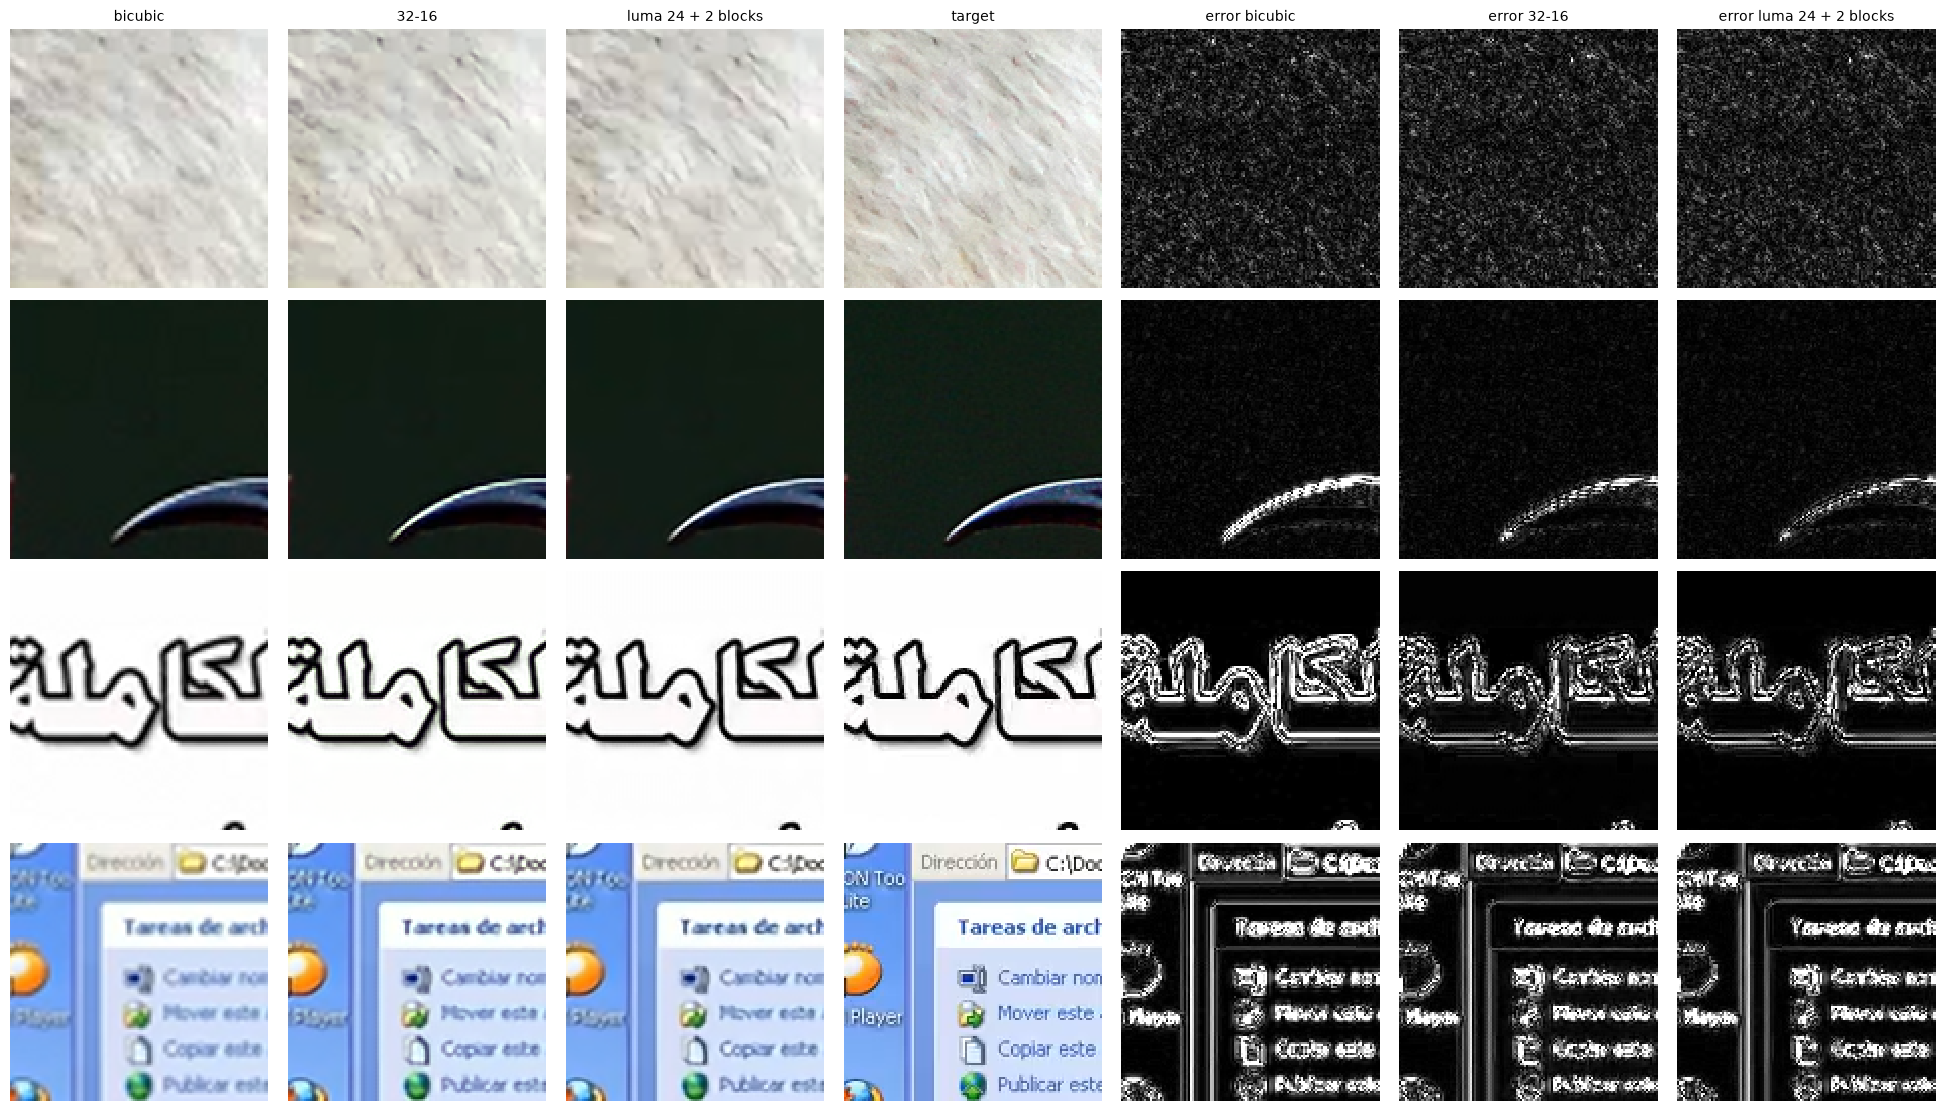

In [14]:
val_set = val_loader.dataset
picks = [i for i in (0, 400, 900, 1600) if i < len(val_set)]
lr = torch.stack([val_set[i][0] for i in picks]).to(DEVICE)
hr = torch.stack([val_set[i][1] for i in picks]).to(DEVICE)
with torch.no_grad():
    outputs = {"bicubic": trim(models.bicubic(lr, SCALE)).clamp(0, 1)}
    for name in dict.fromkeys([CONTROL, best_name]):
        outputs[name] = trim(trained[name].eval()(lr)).clamp(0, 1)

target_y = metrics.rgb_to_yuv(hr)[:, :1]
errors = {}
for name, out in outputs.items():
    error_y = (metrics.rgb_to_yuv(out)[:, :1] - target_y).abs()
    errors[f"error {name}"] = (error_y / 0.15).repeat(1, 3, 1, 1)   # grey = the same in R, G and B
training.show_patches({**outputs, "target": hr, **errors})

## 5. Save and reload

The winner is saved as it ships - merged, if it was trained as branches - with everything
needed to rebuild it. We load it into a fresh model and check it computes the same thing.

In [15]:
BUILDERS = {"PlainUpscaler": models.PlainUpscaler, "LeakyUpscaler": LeakyUpscaler,
            "LumaUpscaler": models.LumaUpscaler, "YuvSplit": YuvSplit}


def shipped_arguments(name):
    """The arguments that rebuild a strategy as it ships (a merged model has no `expand`)."""
    return {key: list(value) if isinstance(value, tuple) else value
            for key, value in STRATEGIES[name][1].items() if key != "expand"}


winner = deployed(trained[best_name])
training.save_checkpoint(CHECKPOINT, winner, architecture=type(winner).__name__,
                         arguments=shipped_arguments(best_name), strategy=best_name,
                         trained_as=type(trained[best_name]).__name__, scale=SCALE, halo=winner.halo,
                         loss="ssim_l1_loss", select="ssim", learning_rate=STRATEGIES[best_name][2],
                         epochs=len(histories[best_name]), best_epoch=bests[best_name]["epoch"],
                         val=results[best_name], val_bicubic=baseline, control_mean=control_mean, seed_spread=spread,
                         degradation=manifest["degradation"])

# rebuild the model from the file alone, the way a later notebook would
checkpoint = training.load_checkpoint(CHECKPOINT)
loaded = BUILDERS[checkpoint["architecture"]](scale=checkpoint["scale"], **checkpoint["arguments"]).to(DEVICE)
loaded.load_state_dict(checkpoint["state_dict"])
training.assert_same_model(winner, loaded)
print("reloaded model is identical")

saved /home/henrik/desktop-streamer-ai/src/upscale/checkpoints/upscale_strategies.pt (62 KB)
reloaded model is identical


### A whole frame

The drawn desktop frame of notebooks 3 and 7, downscaled with bicubic and no codec, so the
numbers compare with theirs.

                        wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
bicubic                 25.82    25.09    29.55    29.01     23.92   0.9437
32-16                   27.10    26.56    29.55    29.02     24.84   0.9609
luma 24 + 2 blocks      27.68    27.26    29.57    29.02     25.23   0.9656


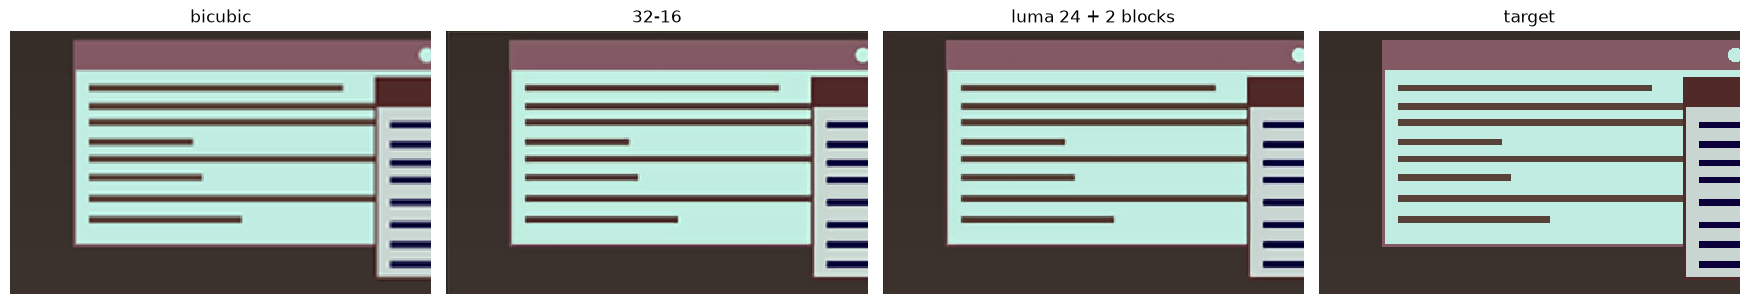

In [16]:
truth = Image.open(sorted(FRAME_DIR.glob("*.png"))[0]).convert("RGB")
truth = truth.crop((0, 0, truth.width - truth.width % SCALE, truth.height - truth.height % SCALE))
small = training.to_tensor(truth.resize((truth.width // SCALE, truth.height // SCALE), Image.BICUBIC))
target = training.to_tensor(truth)
with torch.no_grad():
    upscaled = {"bicubic": models.bicubic(small, SCALE), CONTROL: trained[CONTROL].eval()(small),
                best_name: loaded.eval()(small)}
metrics.print_table({name: metrics.report(image, target) for name, image in upscaled.items()})
Image.fromarray(training.to_image(upscaled[best_name])).save(training.SAMPLE_DIR / "upscaled_strategies.png")

box = (slice(0, 200), slice(0, 320))
panels = {**upscaled, "target": target}
fig, axes = plt.subplots(1, len(panels), figsize=(4.4 * len(panels), 3.4))
for ax, (name, image) in zip(axes, panels.items()):
    ax.imshow(training.to_image(image)[box], interpolation="nearest")
    ax.set_title(name)
    ax.axis("off")
fig.tight_layout()
plt.show()

## 6. Export for the browser

The best `PUBLISH` strategies, one per graph that ships: two strategies that merge into the
same graph (the control and `32-16 reparam`, say) are one model to the browser, so only
the better of them is exported. At the tile a client runs (a 320x180 step,
`5_upscale_geometry.ipynb`), like notebooks 6 and 7: float32, float16 (half the size), and
float16 as one whole 1080p frame. Each graph is checked against the torch model first.

In [17]:
def input_shape(step_height, step_width, halo):
    """The model input for a step: the step plus the halo on every side, as (height, width)."""
    return (step_height + 2 * halo, step_width + 2 * halo)


def check_and_time(info, module, shape, dtype, tolerance):
    """Check a written graph against the torch model, time it on the CPU, print one line."""
    webexport.check_graph(info["path"], module, np.random.rand(1, 3, *shape).astype(np.float32), dtype, tolerance)
    ms = webexport.time_graph(info["path"], shape, dtype)
    webexport.annotate(info, cpu_ms=round(ms, 2))
    print(webexport.summary_line(info, ms))


published, graphs = [], set()
for name in order:   # best first, one per graph that ships
    graph = (type(deployed(trained[name])).__name__, repr(shipped_arguments(name)))
    if graph not in graphs:
        graphs.add(graph)
        published.append(name)
    if len(published) == PUBLISH:
        break

tile_name = f"tile{STEP_WIDTH}x{STEP_HEIGHT}"
for name in published:
    shipped = deployed(trained[name])
    halo = shipped.halo
    tile_shape = input_shape(STEP_HEIGHT, STEP_WIDTH, halo)
    frame_shape = input_shape(FRAME_HEIGHT // SCALE, FRAME_WIDTH // SCALE, halo)
    file, label = f"upscale_strategy_{slug(name)}", f"strategy {name}"

    fp32 = webexport.export(shipped, f"{file}_{tile_name}.onnx", tile_shape, label=f"{label} fp32", halo=halo)
    check_and_time(fp32, shipped, tile_shape, np.float32, tolerance=2e-3)

    fp16 = webexport.to_float16(fp32, f"{file}_fp16_{tile_name}.onnx")
    webexport.write_metadata(fp16["path"], {"label": f"{label} fp16"})
    check_and_time(fp16, shipped, tile_shape, np.float16, tolerance=4e-3)

    frame = webexport.to_frame(fp16, f"{file}_fp16_{tile_name}_frame.onnx", FRAME_WIDTH, FRAME_HEIGHT)
    check_and_time(frame, shipped, frame_shape, np.float16, tolerance=4e-3)
print("compare in a browser: uv run src/upscale/benchmark/main.py")

upscale_strategy_luma_24_2_blocks_tile320x180.onnx     57.7 KB    3.95 ms   Addx3, Concatx1, Convx7, DepthToSpacex1, Relux3


upscale_strategy_luma_24_2_blocks_fp16_tile320x180.onnx   31.0 KB    4.36 ms   Addx3, Concatx1, Convx7, DepthToSpacex1, Relux3


upscale_strategy_luma_24_2_blocks_fp16_tile320x180_frame.onnx   31.0 KB   48.29 ms   Addx3, Concatx1, Convx7, DepthToSpacex1, Relux3


upscale_strategy_32-16_leaky_tile320x180.onnx          39.4 KB    3.13 ms   Addx1, Convx4, DepthToSpacex1, LeakyRelux2


upscale_strategy_32-16_leaky_fp16_tile320x180.onnx     20.8 KB    7.15 ms   Addx1, Convx4, DepthToSpacex1, LeakyRelux2


upscale_strategy_32-16_leaky_fp16_tile320x180_frame.onnx   20.9 KB   85.15 ms   Addx1, Convx4, DepthToSpacex1, LeakyRelux2
compare in a browser: uv run src/upscale/benchmark/main.py


## What to look at

- **The verdict column.** A strategy is better or worse than the control only when its gap
  to the mean of the control's seeds is wider than their spread; "luck" means this set
  cannot tell the two apart.
- **Reparameterization, three times**: `32-16 reparam` against the control, and each luma
  reparam against its plain twin. The control from 3e-4 says how much of the first pair is
  the learning rate rather than the branches.
- **Colour**: `psnr-u` / `psnr-v`. The luma models stay at bicubic by construction; does
  the colour branch of `yuv split` get above it, and is that worth its luma?
- **Cost**: the estimate on the Iris Xe is the one that decides whether a model fits 30 fps
  on a laptop; the benchmark page, opened on the device, gives the real number.